In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import ipywidgets as widgets
from IPython.display import display
import matplotlib as mpl

import warnings
warnings.filterwarnings("ignore")

In [4]:
amount = 0.07
decay_rate = 0.015
Lx = 32
Ly = 32
V = Lx*Ly
num = 300

delta = 0.3
beta = 4.5
delta_mod = 0.3
beta_mod = 4.5


n_list = np.linspace(1, 1000, 1000)
s_list = n_list/(Lx*Ly)*amount/decay_rate

In [5]:
import plotly.graph_objects as go

# Define your function
def beta_c(x, y):
    y0 = num / (Lx * Ly) * y / decay_rate
    return 1 + 1/y0 + 2*x + x*y0 + x**2 * y0

# Generate grid
x = np.linspace(0.0, 0.5, 100)
y = np.linspace(0.01, 0.01, 100)
X, Y = np.meshgrid(x, y)

# Compute Z values
Z = beta_c(X, Y)

# Create interactive 3D surface plot
fig = go.Figure(data=[go.Surface(z=Z, x=X, y=Y)])

fig.update_layout(
    title='Phase Transition Surface',
    scene=dict(
        xaxis_title='delta',
        yaxis_title='eta',
        zaxis_title='beta_c'
    )
)

fig.show()


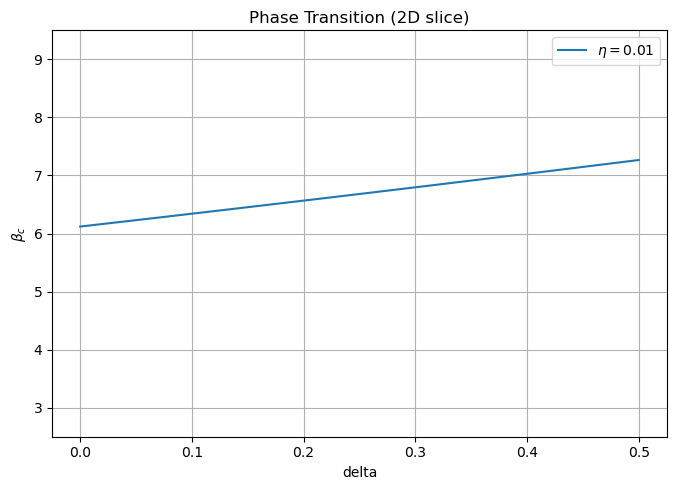

In [10]:
x = np.linspace(0.0, 0.5, 100)
y_val = 0.01  # costante
Z = beta_c(x, y_val)

# Plot 2D
plt.figure(figsize=(7,5))
plt.plot(x, Z, label=f"$\\eta = {y_val}$", color='tab:blue')
plt.xlabel("delta")
plt.ylabel(r"$\beta_c$")
plt.title("Phase Transition (2D slice)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.ylim(2.5, 9.5)
plt.show()


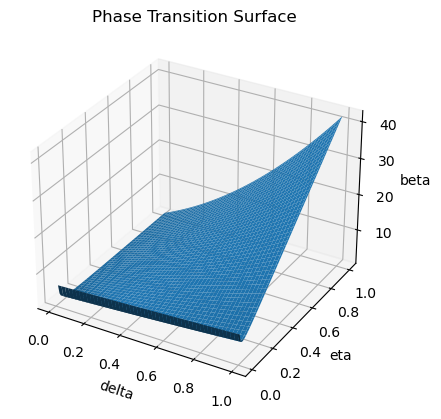

In [8]:
# 3d plot
def beta_c(x, y):
    y0 = num/(Lx*Ly)*y/decay_rate
    return 1+1/y0+2*x+x*y0+x**2*y0

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
x = np.linspace(0.01, 1, 100)
y = np.linspace(0.01, 1, 100)
X, Y = np.meshgrid(x, y)
zs = np.array(beta_c(np.ravel(X), np.ravel(Y)))
Z = zs.reshape(X.shape)

ax.plot_surface(X, Y, Z)

ax.set_xlabel('delta')
ax.set_ylabel('eta')
ax.set_zlabel('beta')
ax.set_title('Phase Transition Surface')

plt.show()

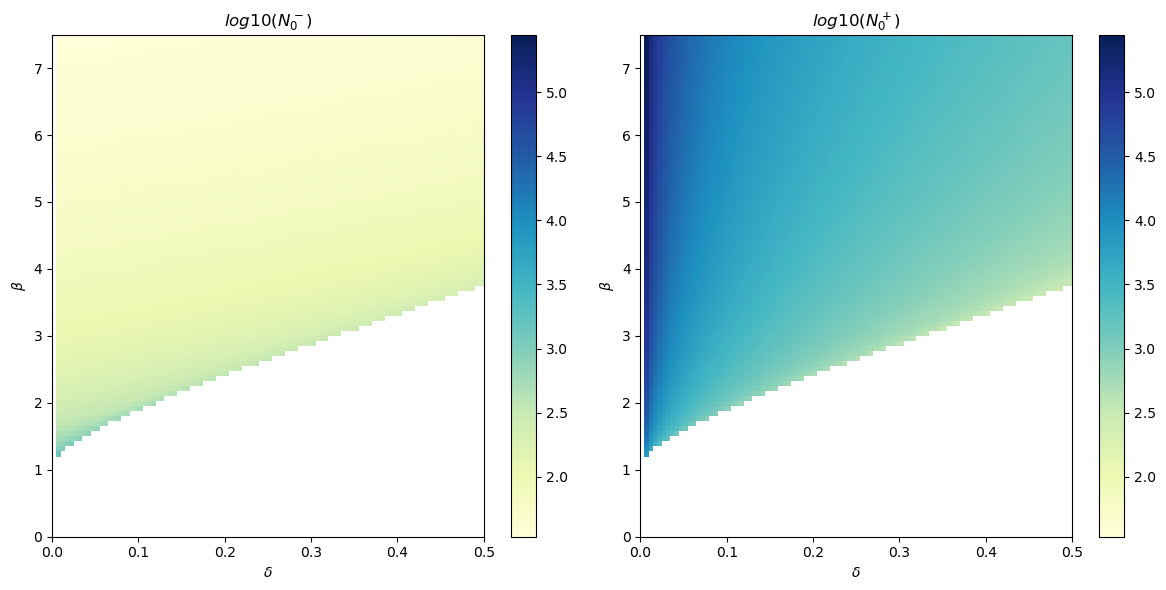

In [5]:
n_grid = 100
d_max = 0.5
b_max = 7.5
delta_list = np.linspace(0, d_max, n_grid+1)
beta_list = np.linspace(0, b_max, n_grid+1)
n0_plus_list = np.zeros((n_grid,n_grid))
n0_minus_list = np.zeros((n_grid,n_grid))
V = Lx*Ly

for i in range(n_grid):
    for j in range(n_grid):
        n0_plus_list[i,j] = (V*decay_rate/amount)/(2*(delta_list[j])*(delta_list[j]+1)) * (beta_list[i] - 1 - 2*delta_list[j] + np.sqrt(beta_list[i]**2 - 2*beta_list[i] - 4*beta_list[i]*delta_list[j] + 1))
        n0_minus_list[i,j] = (V*decay_rate/amount)/(2*(delta_list[j])*(delta_list[j]+1)) * (beta_list[i] - 1 - 2*delta_list[j] - np.sqrt(beta_list[i]**2 - 2*beta_list[i] - 4*beta_list[i]*delta_list[j] + 1))

n0_minus_list = np.log10(np.array(n0_minus_list))
n0_plus_list = np.log10(np.array(n0_plus_list))

cmap = plt.get_cmap('YlGnBu')
cmap.set_bad(color='white')

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[1].set_xlabel(r'$\delta$')
ax[1].set_ylabel(r'$\beta$')
ax[1].set_title(r'$log10(N_0^+$)')

ax[0].set_xlabel(r'$\delta$')
ax[0].set_ylabel(r'$\beta$')
ax[0].set_title(r'$log10(N_0^-$)')

plt.colorbar(ax[1].imshow(n0_plus_list, cmap=cmap, origin='lower',
                           extent=[min(delta_list), max(delta_list), min(beta_list), max(beta_list)], aspect='auto',
                             vmin=np.nanmin(n0_minus_list.flatten()), vmax=np.max(n0_plus_list[np.isfinite(n0_plus_list)])),
                            ax=ax[1])
plt.colorbar(ax[0].imshow(n0_minus_list, cmap=cmap, origin='lower',
                           extent=[min(delta_list), max(delta_list), min(beta_list), max(beta_list)], aspect='auto',
                             vmin=np.nanmin(n0_minus_list.flatten()), vmax=np.max(n0_plus_list[np.isfinite(n0_plus_list)])),
                            ax=ax[0])
plt.tight_layout()
plt.show()

In [6]:
np.nanmin(n0_minus_list.flatten())

1.5341495553490994

In [7]:
np.max(n0_plus_list[np.isfinite(n0_plus_list)])


5.447300729920949

N0_minus: 79.54272614386485
N0_plus: 1552.1056255044857


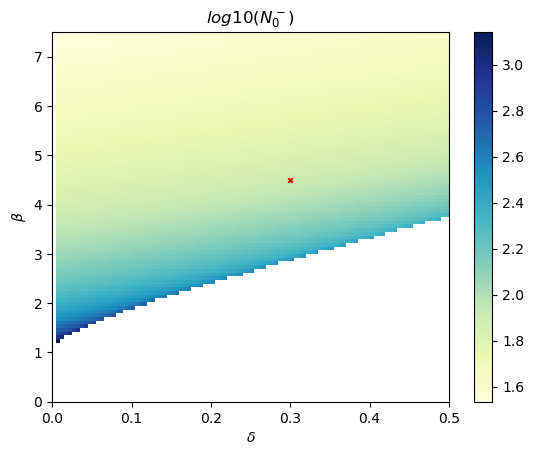

In [8]:
print('N0_minus:', 10**n0_minus_list[int(beta*n_grid/b_max),int(delta*n_grid/d_max)])
print('N0_plus:', 10**n0_plus_list[int(beta*n_grid/b_max),int(delta*n_grid/d_max)])

plt.imshow(n0_minus_list, cmap=cmap, origin='lower',
            extent=[min(delta_list), max(delta_list), min(beta_list), max(beta_list)], aspect='auto')
plt.colorbar()
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
plt.title(r'$log10(N_0^-)$')
plt.scatter(delta, beta, color='red', s=10, marker='x')
plt.show()

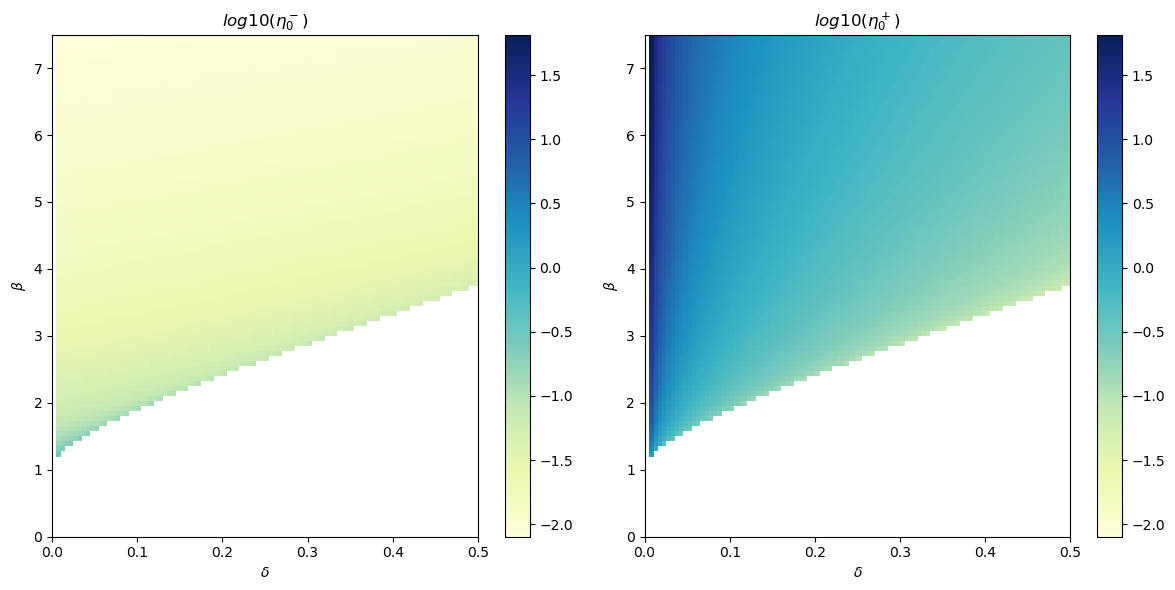

In [9]:
n_grid = 100
d_max = 0.5
b_max = 7.5
N = 300

delta_list = np.linspace(0, d_max, n_grid+1)
beta_list = np.linspace(0, b_max, n_grid+1)
eta_plus_list = np.zeros((n_grid,n_grid))
eta_minus_list = np.zeros((n_grid,n_grid))
V = Lx*Ly

for i in range(n_grid):
    for j in range(n_grid):
        eta_plus_list[i,j] = (V*decay_rate/N)/(2*(delta_list[j])*(delta_list[j]+1)) * (beta_list[i] - 1 - 2*delta_list[j] + np.sqrt(beta_list[i]**2 - 2*beta_list[i] - 4*beta_list[i]*delta_list[j] + 1))
        eta_minus_list[i,j] = (V*decay_rate/N)/(2*(delta_list[j])*(delta_list[j]+1)) * (beta_list[i] - 1 - 2*delta_list[j] - np.sqrt(beta_list[i]**2 - 2*beta_list[i] - 4*beta_list[i]*delta_list[j] + 1))

eta_plus_list = np.log10(np.array(eta_plus_list))
eta_minus_list = np.log10(np.array(eta_minus_list))

cmap = plt.get_cmap('YlGnBu')
cmap.set_bad(color='white')

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[1].set_xlabel(r'$\delta$')
ax[1].set_ylabel(r'$\beta$')
ax[1].set_title(r'$log10(\eta_0^+$)')

ax[0].set_xlabel(r'$\delta$')
ax[0].set_ylabel(r'$\beta$')
ax[0].set_title(r'$log10(\eta_0^-$)')

plt.colorbar(ax[1].imshow(eta_plus_list, cmap=cmap, origin='lower',
                           extent=[min(delta_list), max(delta_list), min(beta_list), max(beta_list)], aspect='auto',
                             vmin=np.nanmin(eta_minus_list.flatten()), vmax=np.max(eta_plus_list[np.isfinite(eta_plus_list)])),
                            ax=ax[1])
plt.colorbar(ax[0].imshow(eta_minus_list, cmap=cmap, origin='lower',
                           extent=[min(delta_list), max(delta_list), min(beta_list), max(beta_list)], aspect='auto',
                             vmin=np.nanmin(eta_minus_list.flatten()), vmax=np.max(eta_plus_list[np.isfinite(eta_plus_list)])),
                            ax=ax[0])
plt.tight_layout()
plt.show()

In [10]:
def den(delta, s0):
    return 1 + delta**2*s0**2 + 2*delta*s0 + delta*s0**2 + s0

In [11]:
mod_list = np.linspace(0, 0.07, 1000)
pow_list = np.linspace(0.07, 0.7, 1000)
#add_list = [1, 5, 10, 20, 30, 50]
#pow_list = [1, 2, 5, 10, 50, 100]
beta_check = np.zeros((len(mod_list), len(pow_list)))
amount_old = 0.07
delta_mod = delta
beta_mod = beta

for i, mod in enumerate(mod_list):
    n_real = 300
    n_mod = 10
    amount = mod

    for j, pow in enumerate(pow_list):
        
        s1 = amount/decay_rate/(Lx*Ly)*n_real
        s2 = pow/decay_rate/(Lx*Ly)*n_mod

        s0 = s1 + s2

        q = s1*beta/den(delta, s0) + s2*beta_mod/den(delta_mod, s0) - 1

        if  q < 0:
            beta_check[i, j] = 0
        else:
            beta_check[i, j] = 1

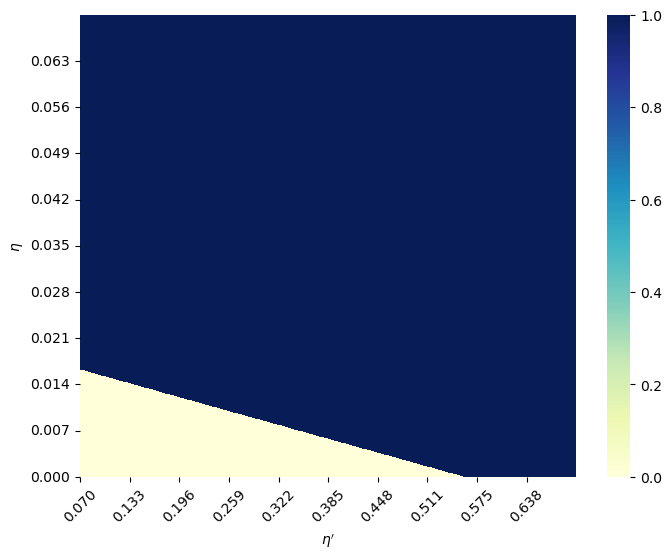

In [13]:
import seaborn as sns

# Creiamo due liste di valori
x_values = pow_list  # 50 valori tra 0 e 100
y_values = mod_list  # 50 valori tra 0 e 100

# Creiamo la heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(beta_check, cmap="YlGnBu")

# Definiamo gli indici ogni 10 elementi
tick_indices = np.arange(0, len(x_values), 100)

# Impostiamo i ticks e i relativi label
ax.set_xticks(tick_indices)
ax.set_xticklabels([f"{x:.3f}" for x in x_values[tick_indices]], rotation=45)

ax.set_yticks(tick_indices)
ax.set_yticklabels([f"{y:.3f}" for y in y_values[tick_indices]])

ax.invert_yaxis()

# Titolo
ax.set_xlabel(r"$\eta'$", fontsize=10)
ax.set_ylabel(r"$\eta$", fontsize=10)

# Mostra il grafico

plt.show()

In [11]:
#add_list = np.linspace(0, num//2, (num//2)*10+1)
#pow_list = np.linspace(0, 100, 1001)
add_list = np.linspace(1, 91, 1000)
pow_list = np.linspace(0, 50, 1000)
#add_list = [1, 5, 10, 20, 30, 50]
#pow_list = [1, 2, 5, 10, 50, 100]
beta_check = np.zeros((len(add_list), len(pow_list)))

for i, add in enumerate(add_list):
    n_real = num
    n_mod = add

    for j, pow in enumerate(pow_list):
        
        s1 = amount/decay_rate/(Lx*Ly)*n_real
        s2 = amount*pow/decay_rate/(Lx*Ly)*n_mod

        s0 = s1 + s2

        q = s1*beta/den(delta, s0) + s2*beta_mod/den(delta_mod, s0) - 1

        if  q < 0:
            beta_check[i, j] = 0
        else:
            beta_check[i, j] = 1

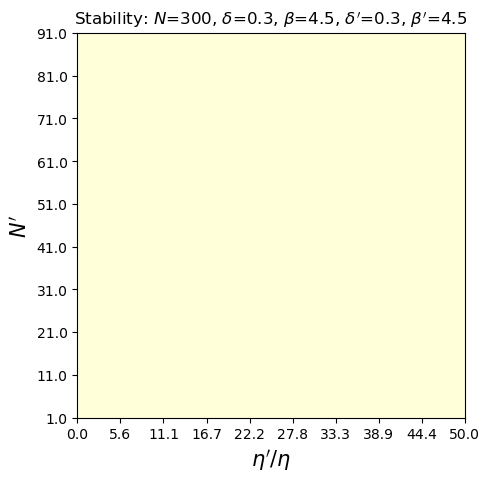

In [12]:
fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(beta_check, aspect='auto', origin='lower', cmap='YlGnBu')

fs = 15 

# Setting labels
ax.set_xlabel(r"$\eta' / \eta$", fontsize=fs)
ax.set_ylabel(r"$N'$", fontsize=fs)

# Display only 10 evenly spaced ticks
xtick_positions = np.linspace(0, len(pow_list) - 1, 10, dtype=int)
ytick_positions = np.linspace(0, len(add_list) - 1, 10, dtype=int)

ax.set_xticks(xtick_positions)
ax.set_yticks(ytick_positions)

# Setting custom tick labels
ax.set_xticklabels([f"{pow_list[pos]:.1f}" for pos in xtick_positions])
ax.set_yticklabels([f"{add_list[pos]:.1f}" for pos in ytick_positions])

# Title and colorbar
ax.set_title(f"Stability: $N$={num}, $\delta$={delta}, $\\beta$={beta}, $\delta'$={delta_mod}, $\\beta'$={beta_mod}")
# fig.colorbar(im, ax=ax)

plt.show()


In [13]:
def pher_func(s,beta,delta):
    return (1+s/(1+s*delta))**beta

In [14]:
pher_func(s0,beta,delta)

733.7375541642787

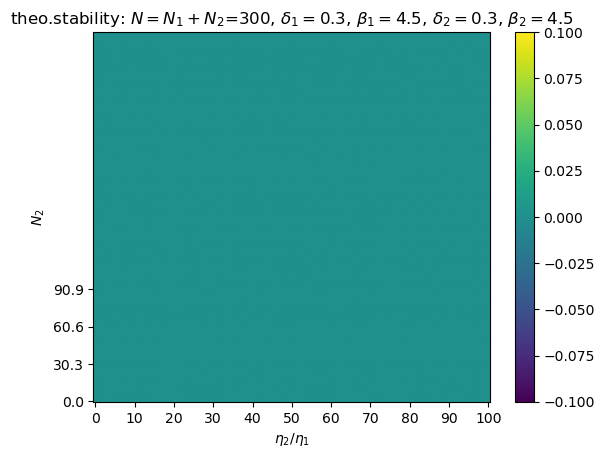

In [15]:
add_list = np.linspace(0, num, num+1)
pow_list = np.linspace(0, 100, 101)
#add_list = [1, 5, 10, 20, 30, 50]
#pow_list = [1, 2, 5, 10, 50, 100]
stab_check = np.zeros((len(add_list), len(pow_list)))

for i, add in enumerate(add_list):
    n_real = num
    n_mod = add
    n = n_mod + n_real

    for j, pow in enumerate(pow_list):

        s1 = amount/decay_rate/(Lx*Ly)*n_real
        s2 = amount*pow/decay_rate/(Lx*Ly)*n_mod

        s0 = s1 + s2
        
        q1 = pow*amount*n_mod*pher_func(s0,beta_mod,delta_mod) + 1*amount*n_real*pher_func(s0,beta,delta)
        q2 = (pow*amount*n_mod + 1*amount*n_real) * (pher_func(s0,beta_mod,delta_mod) + pher_func(s0,beta,delta))

        q = q1 - q2 
        
        if  q < -1000:
            stab_check[i, j] = 0
        else:
            stab_check[i, j] = 1

fig, ax = plt.subplots()
ax.imshow(stab_check, aspect='auto', origin='lower')
ax.set_xlabel("$\eta_2 / \eta_1$")
ax.set_ylabel("$N_2$")
ax.set_xticks(pow_list[::100//10])
ax.set_yticks(mod_list[::num//10])
ax.set_title("theo.stability: $N = N_1+N_2$="+str(num)+", $\delta_1=$"+str(delta)+r", $\beta_1=$"+str(beta)+ ", $\delta_2=$"+str(delta_mod)+r", $\beta_2=$"+str(beta_mod))
# ax.scatter(pow_index, mod_index, color='r', s=10, label="used", marker='x')
plt.colorbar(ax.imshow(stab_check, aspect='auto', origin='lower'), ax=ax)
plt.show()